In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

In [3]:
# Datos de las opciones
df = pd.DataFrame({
    "Opción": ["A", "B", "C"],
    "K": [90, 100, 120],
    "T": [1/12, 3/12, 1],
    "Prima": [12, 8, 5],
    "Delta": [0.85, 0.50, 0.20],
    "Vega": [0.05, 0.25, 0.40],
    "Theta": [-0.10, -0.03, -0.01]
})

print(df)

  Opción    K         T  Prima  Delta  Vega  Theta
0      A   90  0.083333     12   0.85  0.05  -0.10
1      B  100  0.250000      8   0.50  0.25  -0.03
2      C  120  1.000000      5   0.20  0.40  -0.01


## Parte 1: Observación

1. ¿Cuál opción parece más sensible a cambio en el precio de la acción?

- Opción A, porque tiene el Delta más alto (0.85). Esto significa que su precio cambia aproximadamente 0.85 ante un cambio de $1 en la acción.


2. ¿Cuál opción parece más sensible a cambios en volatilidad?

- Opción C, porque tiene la Vega más alta (0.40). Por lo tanto, su precio es el más sensible a cambios en la volatilidad.

3. ¿Cuál opción parece deteriorarse más rápidamente con el paso del tiempo?

- Opción A, porque tiene el Theta más negativo (-0.10). Esto significa que pierde valor más rápidamente conforme pasa el tiempo.


4. ¿Cuál opción parece tener el comportamiento más parecido al de la acción?

- Opción A, porque tiene un Delta de 0.85, el valor más cercano a 1. Por lo tanto, su precio tiende a moverse de manera más similar al precio de la acción.

5. ¿Cuál acción parece depender más de que ocurra un evento importante en el futuro?

- Opción C, porque tiene el plazo más largo (1 año) y la Vega más alta (0.40), por lo que tiene mayor exposición a cambios en la volatilidad durante el periodo.

## Parte 2: Escenarios de mercado

#### Para cada escenario explica qué opción comprarías y cuál evitarías. Justifica tus respuestas usando tu entendimiento de sensibilidades.

#### Escenario A:
 - Piensas que la acción aumentará gradualmente durante los próximos meses. No crees que vaya a cambiar la volatilidad.

     - Compraría la Opción A y evitaría la Opción C.
    La acción subiría gradualmente y no se espera un cambio importante en la volatilidad. La Opción A tiene el Delta más alto (0.85), por lo que es la más sensible a una subida del precio de la acción. La Opción C tiene un Delta menor (0.20) y depende más de cambios en volatilidad.
     
#### Escenario B:
- Dentro de dos semanas la empresa anunciará un nuevo producto. No sabes si el precio subirá o bajará, pero esperas un cambio brusco.

    - Compraría la Opción C y evitaría la Opción A.
    El anuncio puede provocar un movimiento brusco, aunque no sabemos en qué dirección. La Opción C tiene la Vega más alta (0.40), por lo que es la más sensible a un aumento de la volatilidad. Además, tiene un plazo de un año. La Opción A tiene una Vega baja (0.05) y un Theta más negativo (-0.10).

#### Escenario C:
- Piensas que la acción se mantendrá muy estable.

    - Evitaría comprar una opción y, si tuviera que elegir, consideraría la Opción C.
    Si la acción permanece estable, las opciones pueden perder valor por el paso del tiempo. La Opción A es la que tiene el Theta más negativo (-0.10), por lo que su deterioro temporal es mayor. La Opción C tiene el Theta menos negativo (-0.01).


#### Escenario D:
- Crees que va a haber una caída significativa del precio de la acción.


    - Compraría la Opción C y evitaría la Opción A.
    Si esperamos una caída significativa de la acción, la Opción C es la más adecuada de las tres porque tiene el menor Delta (0.20) y un precio de ejercicio de 120, por lo que tiene mayor posibilidad de beneficiarse si la acción cae desde 100 hacia niveles inferiores. La Opción A tiene un Delta de 0.85 y un precio de ejercicio de $90, por lo que está más expuesta a movimientos alcistas de la acción.



#### Escenario E:
- Crees que el mercado está subestimando la incertidumbre futura.


    - Compraría la Opción C y evitaría la Opción A.
    Si se considera que el mercado está subestimando la incertidumbre futura, interesa una opción con mayor sensibilidad a la volatilidad. La Opción C tiene la Vega más alta (0.40), mientras que A tiene una Vega de solo 0.05.

In [4]:
# Datos
meses = ["Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre"]

precios = np.array([100, 102, 101, 105, 103, 110])
volatilidad = np.array([0.20, 0.25, 0.30, 0.28, 0.22, 0.20])

# Parámetros iniciales
r = 0.05
K = 100
V0 = 6.8887

Delta = 0.5977
Gamma = 0.02736
Vega = 0.2814
Theta = -8.116

dt = 1/12

### Greeks 

In [5]:
dS = [np.nan]
dsigma = [np.nan]
valores_greeks = [V0]

V = V0

for i in range(1, len(precios)):

    cambio_S = precios[i] - precios[i-1]
    cambio_sigma = volatilidad[i] - volatilidad[i-1]

    V = (
        V
        + Delta * cambio_S
        + 0.5 * Gamma * cambio_S**2
        + Vega * cambio_sigma
        + Theta * dt
    )

    dS.append(cambio_S)
    dsigma.append(cambio_sigma)
    valores_greeks.append(V)

### Black-Scholes

In [6]:
tiempo = np.array([6, 5, 4, 3, 2, 1]) / 12

valores_bs = []

for S, sigma, T in zip(precios, volatilidad, tiempo):

    d1 = (
        np.log(S/K)
        + (r + sigma**2/2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    call = (
        S * norm.cdf(d1)
        - K * np.exp(-r*T) * norm.cdf(d2)
    )

    valores_bs.append(call)

### Monte Carlo

In [15]:
# Monte Carlo
M = 10000

valores_mc = []

np.random.seed(42)

for S, sigma, T in zip(precios, volatilidad, tiempo):

    # Simular precio al vencimiento
    Z = np.random.normal(0, 1, M)

    ST = S * np.exp(
        (r - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z
    )

    # Payoff de la Call
    payoff = np.maximum(ST - K, 0)

    # Valor presente
    precio_mc = np.exp(-r*T) * payoff.mean()

    valores_mc.append(precio_mc)

### Tabla de Greeks

In [11]:
tabla_greeks = pd.DataFrame({
    "Mes": meses,
    "Precio": precios,
    "Volatilidad": volatilidad,
    "dS": dS,
    "dsigma": dsigma,
    "Valor aproximado (Greeks)": valores_greeks
})

display(tabla_greeks)

,Mes,Precio,Volatilidad,dS,dsigma,Valor aproximado (Greeks)
0,Mayo,100,0.20,NaN,NaN,6.888700
1,Junio,102,0.25,2.0,0.05,7.476557
2,Julio,101,0.30,-1.0,0.05,6.230273
3,Agosto,105,0.28,4.0,-0.02,8.157992
4,Septiembre,103,0.22,-2.0,-0.06,6.324095
5,Octubre,110,0.20,7.0,-0.02,10.496353


### Tabla de Black-Scholes

In [12]:
tabla_bs = pd.DataFrame({
    "Mes": meses,
    "Precio": precios,
    "Volatilidad": volatilidad,
    "Tiempo restante": tiempo,
    "Valor Black-Scholes": valores_bs
})

display(tabla_bs)

,Mes,Precio,Volatilidad,Tiempo restante,Valor Black-Scholes
0,Mayo,100,0.20,0.500000,6.888729
1,Junio,102,0.25,0.416667,8.662111
2,Julio,101,0.30,0.333333,8.286009
3,Agosto,105,0.28,0.250000,9.341809
4,Septiembre,103,0.22,0.166667,5.852960
5,Octubre,110,0.20,0.083333,10.520232


### Black-Scholes vs Greeks vs Monte Carlo

In [18]:
error = np.abs(
    tabla_comparacion["Greeks"] - tabla_comparacion["Black-Scholes"]
)


tabla_comparacion = pd.DataFrame({
    "Mes": meses,
    "Greeks": valores_greeks,
    "Black-Scholes": valores_bs,
    "Monte Carlo": valores_mc,
    "Error Absoluto": error,
    
})

display(tabla_comparacion)






,Mes,Greeks,Black-Scholes,Monte Carlo,Error Absoluto
0,Mayo,6.888700,6.888729,6.887435,0.000029
1,Junio,7.476557,8.662111,8.792000,1.185555
2,Julio,6.230273,8.286009,8.109579,2.055736
3,Agosto,8.157992,9.341809,9.300549,1.183817
4,Septiembre,6.324095,5.852960,5.898737,0.471134
5,Octubre,10.496353,10.520232,10.544880,0.023879


## Grafica 

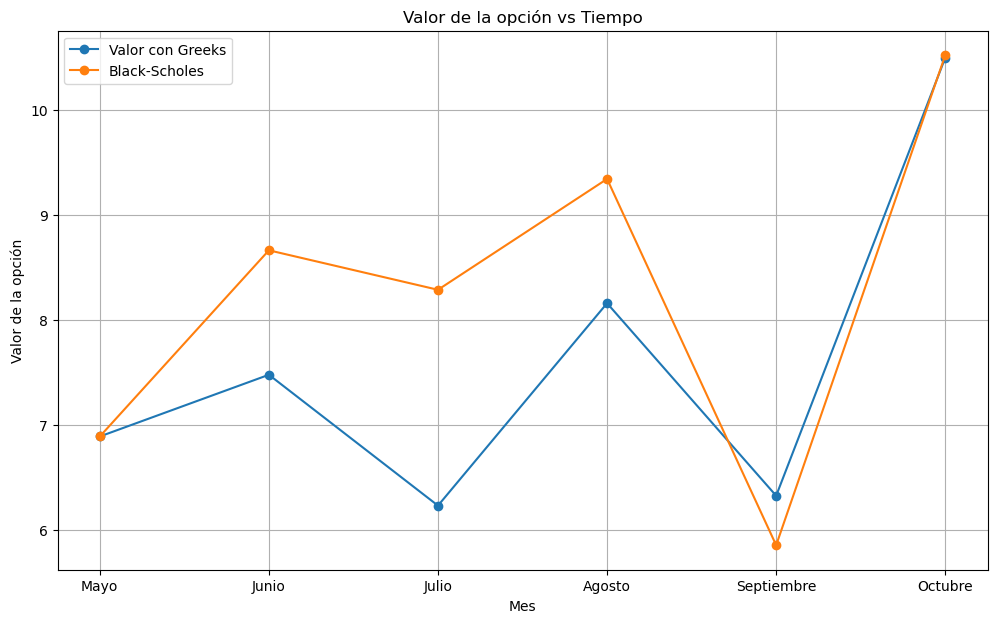

In [20]:
plt.figure(figsize=(12, 7))

plt.plot(
    meses,
    valores_greeks,
    marker='o',
    label='Valor con Greeks'
)

plt.plot(
    meses,
    valores_bs,
    marker='o',
    label='Black-Scholes'
)

plt.title("Valor de la opción vs Tiempo")
plt.xlabel("Mes")
plt.ylabel("Valor de la opción")

plt.legend()
plt.grid(True)

plt.show()

### Ultima parte 

1. ¿Los greeks iniciales describen con precisión toda la trayectoria?

    - No completamente. Los Greeks iniciales dan una aproximación del valor de la opción. Funcionan bien cerca de las condiciones iniciales, pero conforme cambian el precio, la volatilidad y el tiempo, la aproximación puede alejarse del valor de Black-Scholes.



2. ¿En qué mes apareció el error más grande?


    - El error más grande apareció en julio con 2.055736 en Error Absoluto


3. ¿Qué factor parece contribuir más al error?


    - El cambio en el precio de la acción parece contribuir de manera importante, especialmente cuando los movimientos son grandes. También influyen los cambios en volatilidad y el paso del tiempo.



4. ¿Por qué los Greeks funcionan mejor para movimientos pequeños que para movimientos grandes?


    - Porque la aproximación con Greeks utiliza una expansión local alrededor del valor inicial. Cuando el cambio en el precio es pequeño, la aproximación permanece cerca del valor real. Cuando el movimiento es grande, aparecen errores porque los Greeks también cambian y ya no son constantes.



5. Si la trayectoria fuera mucho más volátil, ¿esperarías errores menores? ¿por qué?


    - Esperaría errores mayores, porque habría cambios más grandes en el precio y en la volatilidad. Los Greeks iniciales tendrían que aproximar movimientos más alejados del punto inicial, reduciendo la precisión de la aproximación.


6. Conclusión

    - Los Greeks son útiles para estimar rápidamente el valor de una opción ante cambios pequeños en el precio, volatilidad y tiempo. Sin embargo, en movimientos grandes la aproximación puede presentar errores importantes. Greeks son una buena herramienta de aproximación, pero Black-Scholes proporciona una valoración más completa cuando las condiciones de la opción cambian a lo largo del tiempo.